# STKI Football Player Finder
## Exploratory Data Analysis (EDA)

### Tujuan
Exploratory Data Analysis (EDA) dilakukan untuk memahami struktur, karakteristik, dan kualitas dataset pemain sepak bola sebelum digunakan dalam pengembangan aplikasi pencarian pemain.

### Tahapan Analisis
1. Memuat dan memahami dataset.
2. Memeriksa struktur dan tipe data.
3. Mengidentifikasi nilai kosong dan duplikasi.
4. Menganalisis karakteristik pemain berdasarkan posisi, kewarganegaraan, klub, dan usia.
5. Menyusun kesimpulan sebagai dasar preprocessing data.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 50)

plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["figure.dpi"] = 110

print("Library berhasil diimpor.")

Library berhasil diimpor.


In [2]:
dataset_path = Path(
    r"D:\STKI_FootballFinder\dataset\player_profiles.csv"
)

df = pd.read_csv(dataset_path, low_memory=False)

print("Dataset berhasil dibaca!")

Dataset berhasil dibaca!


In [3]:
jumlah_baris = df.shape[0]
jumlah_kolom = df.shape[1]

print(f"Jumlah pemain/data : {jumlah_baris:,}")
print(f"Jumlah kolom       : {jumlah_kolom:,}")
print(f"Total sel data     : {jumlah_baris * jumlah_kolom:,}")

Jumlah pemain/data : 92,671
Jumlah kolom       : 34
Total sel data     : 3,150,814


In [4]:
df.head(10)

,player_id,player_slug,player_name,player_image_url,name_in_home_country,date_of_birth,place_of_birth,country_of_birth,height,citizenship,is_eu,position,main_position,foot,current_club_id,current_club_name,joined,contract_expires,outfitter,social_media_url,player_agent_id,player_agent_name,contract_option,date_of_last_contract_extension,on_loan_from_club_id,on_loan_from_club_name,contract_there_expires,second_club_url,second_club_name,third_club_url,third_club_name,fourth_club_url,fourth_club_name,date_of_death
0,1,silvio-adzic,Silvio Adzic (1),https://img.a.transfermarkt.technology/portrai...,NaN,1980-09-23,Grünstadt,Germany,0.0,Germany,True,Attack - Right Winger,Attack,NaN,123,Retired,2017-07-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,100011,everton-silva,Éverton Silva (100011),https://img.a.transfermarkt.technology/portrai...,Éverton José Modesto da Silva,1988-08-04,São João de Meriti,Brazil,171.0,Brazil,False,Defender - Right-Back,Defender,right,515,Without Club,2025-03-01,NaN,NaN,NaN,8373.0,RN Sports,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,10,miroslav-klose,Miroslav Klose (10),https://img.a.transfermarkt.technology/portrai...,Miroslav Josef Klose,1978-06-09,Opole,Germany,184.0,Germany,True,Attack - Centre-Forward,Attack,right,123,Retired,2016-07-01,NaN,NaN,http://miroslavklose.de/,1126.0,ASBW Sport Marketing,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,10001,john-thompson,John Thompson (10001),https://img.a.transfermarkt.technology/portrai...,John Paul Thompson,1981-10-12,Dublin,Ireland,183.0,Ireland,True,Defender - Right-Back,Defender,both,123,Retired,2013-07-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,100001,carlos-auzqui,Carlos Auzqui (100001),https://img.a.transfermarkt.technology/portrai...,Carlos Daniel Auzqui,1991-03-16,Longchamps,Argentina,180.0,Argentina,False,Attack - Right Winger,Attack,right,14554,Club Atlético Tucumán,2025-01-30,2025-12-31,NaN,http://www.instagram.com/auzqui91/,5240.0,OLLER GROUP,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,1000152,sodick-adejumo,Sodick Adejumo (1000152),https://img.a.transfermarkt.technology/portrai...,NaN,2004-01-08,Saint-Denis,France,198.0,France Nigeria,True,Midfield - Defensive Midfield,Midfield,right,75,Unknown,2024-12-07,NaN,NaN,NaN,1406.0,YOU FIRST,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,1000153,matheo-sanchez,Matheo Sánchez (1000153),https://img.a.transfermarkt.technology/portrai...,Matheo Manuel André Sánchez,2003-03-13,Belfort,France,186.0,France,True,Attack - Left Winger,Attack,right,42457,Club Atlético Antoniano,2025-07-11,2026-06-30,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,10002,brian-cash,Brian Cash (10002),https://img.a.transfermarkt.technology/portrai...,NaN,1982-11-24,Dublin,Ireland,175.0,Ireland,True,Midfield - Right Midfield,Midfield,right,123,Retired,2011-07-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,100020,sergiy-zagynaylov,Sergiy Zagynaylov (100020),https://img.a.transfermarkt.technology/portrai...,Загинайлов Сергій Геннадійович,1991-01-03,"Brovary, Kyiv Oblast",Ukraine,181.0,Ukraine,False,Attack - Centre-Forward,Attack,left,111355,1.FC Höllental,2023-07-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,1000161,lenny-stoltz,Lenny Stoltz (1000161),https://img.a.transfermarkt.technology/portrai...,Lenny Stoltz Kachouri,2000-06-13,Wissembourg,France,182.0,France Tunisia,True,Attack - Centre-Forward,Attack,left,21274,US Mondorf-Les-Bains,2025-07-29,2028-06-30,NaN,NaN,2759.0,BESTWAY SOCCER ...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
for nomor, kolom in enumerate(df.columns, start=1):
    print(f"{nomor:02}. {kolom}")

01. player_id
02. player_slug
03. player_name
04. player_image_url
05. name_in_home_country
06. date_of_birth
07. place_of_birth
08. country_of_birth
09. height
10. citizenship
11. is_eu
12. position
13. main_position
14. foot
15. current_club_id
16. current_club_name
17. joined
18. contract_expires
19. outfitter
20. social_media_url
21. player_agent_id
22. player_agent_name
23. contract_option
24. date_of_last_contract_extension
25. on_loan_from_club_id
26. on_loan_from_club_name
27. contract_there_expires
28. second_club_url
29. second_club_name
30. third_club_url
31. third_club_name
32. fourth_club_url
33. fourth_club_name
34. date_of_death


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 92671 entries, 0 to 92670
Data columns (total 34 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   player_id                        92671 non-null  int64  
 1   player_slug                      92671 non-null  object 
 2   player_name                      92151 non-null  object 
 3   player_image_url                 92671 non-null  object 
 4   name_in_home_country             49653 non-null  object 
 5   date_of_birth                    91665 non-null  object 
 6   place_of_birth                   76038 non-null  object 
 7   country_of_birth                 76026 non-null  object 
 8   height                           92667 non-null  float64
 9   citizenship                      92614 non-null  object 
 10  is_eu                            92671 non-null  bool   
 11  position                         92669 non-null  object 
 12  main_position     

## 2. Pemeriksaan Missing Values

Pemeriksaan missing values dilakukan untuk mengetahui jumlah dan persentase nilai kosong pada setiap kolom. Hasil pemeriksaan digunakan untuk menentukan penanganan data sebelum proses pengembangan aplikasi pencarian pemain.

In [7]:
missing_count = df.isnull().sum()

missing_count = missing_count[missing_count > 0]

missing_count = missing_count.sort_values(ascending=False)

missing_count

fourth_club_name                   92670
fourth_club_url                    92670
third_club_url                     92629
third_club_name                    92629
date_of_death                      92399
second_club_url                    91693
second_club_name                   91693
contract_there_expires             90165
contract_option                    89100
on_loan_from_club_id               88913
on_loan_from_club_name             88913
outfitter                          86713
date_of_last_contract_extension    84308
social_media_url                   72334
player_agent_id                    54614
contract_expires                   54005
player_agent_name                  49791
name_in_home_country               43018
foot                               23488
country_of_birth                   16645
place_of_birth                     16633
joined                              3382
date_of_birth                       1006
player_name                          520
citizenship     

In [8]:
missing_percent = (df.isnull().mean() * 100)

missing_percent = missing_percent[missing_percent > 0]

missing_percent = missing_percent.sort_values(ascending=False)

missing_percent = missing_percent.round(2)

missing_percent

fourth_club_name                   100.00
fourth_club_url                    100.00
third_club_url                      99.95
third_club_name                     99.95
date_of_death                       99.71
second_club_url                     98.94
second_club_name                    98.94
contract_there_expires              97.30
contract_option                     96.15
on_loan_from_club_id                95.94
on_loan_from_club_name              95.94
outfitter                           93.57
date_of_last_contract_extension     90.98
social_media_url                    78.05
player_agent_id                     58.93
contract_expires                    58.28
player_agent_name                   53.73
name_in_home_country                46.42
foot                                25.35
country_of_birth                    17.96
place_of_birth                      17.95
joined                               3.65
date_of_birth                        1.09
player_name                       

In [9]:
missing_table = pd.DataFrame({
    "Jumlah Missing": df.isnull().sum(),
    "Persentase Missing (%)": df.isnull().mean() * 100
})

missing_table = missing_table[
    missing_table["Jumlah Missing"] > 0
].sort_values(
    by="Persentase Missing (%)",
    ascending=False
)

missing_table["Persentase Missing (%)"] = (
    missing_table["Persentase Missing (%)"].round(2)
)

missing_table

,Jumlah Missing,Persentase Missing (%)
fourth_club_name,92670,100.00
fourth_club_url,92670,100.00
third_club_url,92629,99.95
third_club_name,92629,99.95
date_of_death,92399,99.71
second_club_url,91693,98.94
second_club_name,91693,98.94
contract_there_expires,90165,97.30
contract_option,89100,96.15
on_loan_from_club_id,88913,95.94


## 3. Pemeriksaan Data Duplikat

Pemeriksaan data duplikat dilakukan untuk mengetahui apakah terdapat baris atau identitas pemain yang tercatat lebih dari satu kali. Pemeriksaan ini membantu menjaga kualitas data sebelum digunakan dalam aplikasi pencarian pemain.

In [10]:
jumlah_duplikat_baris = df.duplicated().sum()

print("Jumlah baris duplikat:", jumlah_duplikat_baris)

Jumlah baris duplikat: 0


In [11]:
jumlah_duplikat_id = df["player_id"].duplicated().sum()

print("Jumlah player_id duplikat:", jumlah_duplikat_id)

Jumlah player_id duplikat: 0


In [12]:
print("Jumlah kategori posisi utama:")
print(df["main_position"].nunique())

print("\nJumlah pemain per posisi utama:")
print(df["main_position"].value_counts(dropna=False))

Jumlah kategori posisi utama:
4

Jumlah pemain per posisi utama:
main_position
Defender      29733
Midfield      28373
Attack        24287
Goalkeeper    10276
NaN               2
Name: count, dtype: int64


In [13]:
print("Jumlah kategori posisi spesifik:")
print(df["position"].nunique())

print("\n10 posisi spesifik dengan jumlah pemain terbanyak:")
print(df["position"].value_counts().head(10))

Jumlah kategori posisi spesifik:
17

10 posisi spesifik dengan jumlah pemain terbanyak:
position
Defender - Centre-Back           15074
Attack - Centre-Forward          12070
Goalkeeper                       10276
Midfield - Central Midfield       9546
Midfield - Defensive Midfield     6999
Defender - Right-Back             6502
Defender - Left-Back              6116
Midfield - Attacking Midfield     5821
Attack - Right Winger             4790
Attack - Left Winger              4756
Name: count, dtype: int64


In [14]:
print("Jumlah nama klub/kategori berbeda:")
print(df["current_club_name"].nunique())

print("\n15 nilai terbanyak pada kolom klub:")
print(df["current_club_name"].value_counts().head(15))

Jumlah nama klub/kategori berbeda:
11848

15 nilai terbanyak pada kolom klub:
current_club_name
Retired                       23380
Without Club                   8599
Unknown                        1930
---                             271
Career break                    102
Arsenal FC                       58
Botafogo FC                      53
Pro Vercelli Primavera           47
Reggiana Primavera               45
Medialiga (RU)                   44
Gangwon FC                       44
Lecco Primavera                  41
Clube do Remo (PA)               40
Gimcheon Sangmu                  40
Guarani Futebol Clube (SP)       39
Name: count, dtype: int64


In [15]:
status_klub = [
    "Retired",
    "Without Club",
    "Unknown",
    "---",
    "Career break"
]

for status in status_klub:
    jumlah = (df["current_club_name"] == status).sum()
    print(f"{status}: {jumlah:,} pemain")

Retired: 23,380 pemain
Without Club: 8,599 pemain
Unknown: 1,930 pemain
---: 271 pemain
Career break: 102 pemain


In [16]:
print("Jumlah nilai kewarganegaraan berbeda:")
print(df["citizenship"].nunique())

print("\n15 nilai kewarganegaraan terbanyak:")
print(df["citizenship"].value_counts().head(15))

Jumlah nilai kewarganegaraan berbeda:
2689

15 nilai kewarganegaraan terbanyak:
citizenship
Italy            12574
Spain             5936
Brazil            5484
England           4131
France            3988
Türkiye           3172
Germany           3147
Portugal          2210
Argentina         1922
Poland            1788
Mexico            1761
Belgium           1725
Netherlands       1628
United States     1373
Hungary           1319
Name: count, dtype: int64


In [17]:
citizenship_sample = df[
    df["citizenship"].str.contains(r"\s{2,}", na=False)
]

print("Jumlah baris dengan spasi berulang pada citizenship:")
print(len(citizenship_sample))

citizenship_sample[["player_name", "citizenship"]].head(10)

Jumlah baris dengan spasi berulang pada citizenship:
19956


,player_name,citizenship
5,Sodick Adejumo (1000152),France Nigeria
9,Lenny Stoltz (1000161),France Tunisia
10,Facundo Canete (1000253),United States Argentina
11,Brian Romero (1000274),United States Mexico
12,Nimfasha Berchimas (1000273),United States Burundi
13,Malcolm Rangon (1000148),France Martinique
14,Mauricio Gonçalves da Moura (1000150),Cape Verde France
17,Wes Morgan (10003),Jamaica England
18,Elie Kayembe (1000146),France DR Congo
19,Liridon Osmanaj (100012),Slovenia Albania


In [18]:
contoh_citizenship = df.loc[
    df["citizenship"].str.contains(r"\s{2,}", na=False),
    "citizenship"
].head(10)

for nilai in contoh_citizenship:
    print(repr(nilai))

'France  Nigeria'
'France  Tunisia'
'United States  Argentina'
'United States  Mexico'
'United States  Burundi'
'France  Martinique'
'Cape Verde  France'
'Jamaica  England'
'France  DR Congo'
'Slovenia  Albania'


In [19]:
print("Statistik tinggi badan pemain (cm):")
print(df["height"].describe().round(2))

print("\nJumlah tinggi badan kosong:")
print(df["height"].isnull().sum())

Statistik tinggi badan pemain (cm):
count    92667.00
mean       144.62
std         73.37
min          0.00
25%        171.00
50%        180.00
75%        185.00
max        210.00
Name: height, dtype: float64

Jumlah tinggi badan kosong:
4


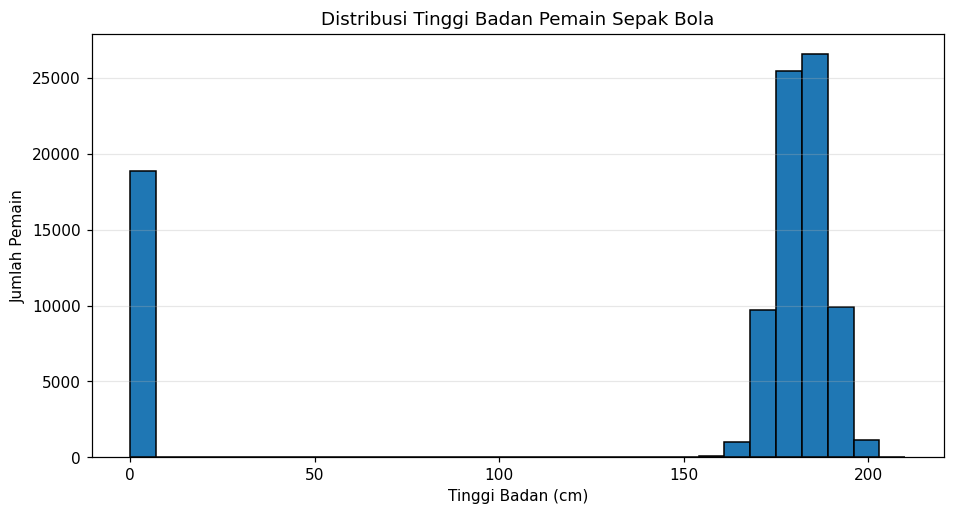

In [20]:
plt.figure(figsize=(10, 5))

plt.hist(
    df["height"].dropna(),
    bins=30,
    edgecolor="black"
)

plt.title("Distribusi Tinggi Badan Pemain Sepak Bola")
plt.xlabel("Tinggi Badan (cm)")
plt.ylabel("Jumlah Pemain")
plt.grid(axis="y", alpha=0.3)
plt.show()

In [21]:
print("Jumlah tinggi badan <= 0 cm:")
print((df["height"] <= 0).sum())

print("\nData pemain dengan tinggi badan <= 0 cm:")
df.loc[
    df["height"] <= 0,
    ["player_name", "height", "main_position", "current_club_name"]
].head(20)

Jumlah tinggi badan <= 0 cm:
18867

Data pemain dengan tinggi badan <= 0 cm:


,player_name,height,main_position,current_club_name
0,Silvio Adzic (1),0.0,Attack,Retired
10,Facundo Canete (1000253),0.0,Midfield,Carolina Core FC
11,Brian Romero (1000274),0.0,Attack,Charlotte FC
22,Michael Dunne (1000307),0.0,Defender,Portland Pilots (University of Portland)
26,Alexis Moreno (1000312),0.0,Midfield,Portland Timbers 2
32,Cédric Janvier (100073),0.0,Defender,Retired
35,Héritier Lunda (100075),0.0,Defender,Unknown
36,Fausto Salicioni (1000693),0.0,Attack,Virtus Entella Primavera
37,Parker Smith (1000774),0.0,Goalkeeper,Retired
38,Julian Bravo (1000714),0.0,Defender,Oakland Roots SC


In [22]:
print("Jumlah tinggi badan < 140 cm:")
print((df["height"] < 140).sum())

print("\nStatistik tinggi badan setelah mengecualikan nilai <= 0:")
height_valid = df.loc[df["height"] > 0, "height"]

print(height_valid.describe().round(2))

Jumlah tinggi badan < 140 cm:
18868

Statistik tinggi badan setelah mengecualikan nilai <= 0:
count    73800.00
mean       181.59
std          6.72
min          2.00
25%        177.00
50%        182.00
75%        186.00
max        210.00
Name: height, dtype: float64


In [23]:
print("Jumlah tinggi badan di bawah 140 cm, termasuk 0:")
print((df["height"] < 140).sum())

print("\nPemain dengan tinggi badan antara 1–139 cm:")
df.loc[
    (df["height"] > 0) & (df["height"] < 140),
    ["player_name", "height", "main_position", "current_club_name"]
].sort_values("height").head(20)


Jumlah tinggi badan di bawah 140 cm, termasuk 0:
18868

Pemain dengan tinggi badan antara 1–139 cm:


,player_name,height,main_position,current_club_name
6840,NaN,2.0,Defender,US Casati Arcore


In [24]:
print("20 nilai tinggi badan terendah yang lebih dari 0:")
print(
    df.loc[df["height"] > 0, "height"]
    .sort_values()
    .head(20)
    .to_list()
)

20 nilai tinggi badan terendah yang lebih dari 0:
[2.0, 152.0, 153.0, 154.0, 154.0, 155.0, 155.0, 155.0, 156.0, 158.0, 158.0, 158.0, 158.0, 158.0, 158.0, 159.0, 159.0, 159.0, 159.0, 159.0]


In [25]:
print("Jumlah kategori kaki dominan:")
print(df["foot"].nunique())

print("\nJumlah pemain berdasarkan kaki dominan:")
print(df["foot"].value_counts(dropna=False))

Jumlah kategori kaki dominan:
3

Jumlah pemain berdasarkan kaki dominan:
foot
right    49186
NaN      23488
left     16870
both      3127
Name: count, dtype: int64


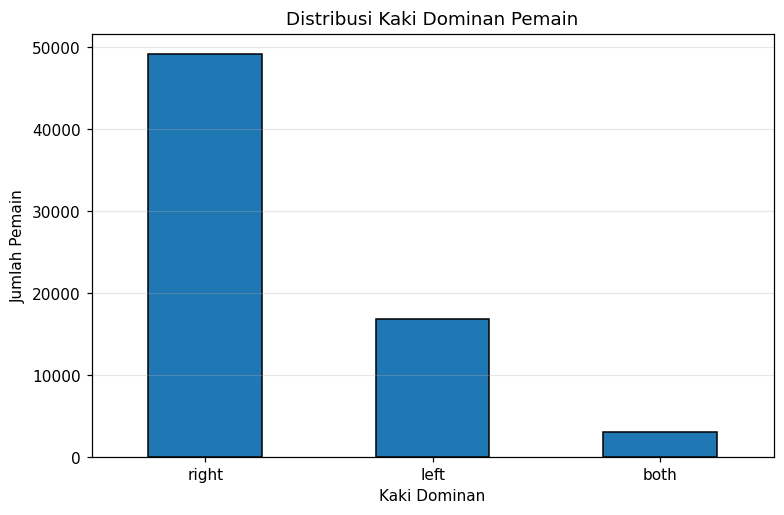

In [26]:
foot_counts = df["foot"].value_counts()

plt.figure(figsize=(8, 5))
foot_counts.plot(kind="bar", edgecolor="black")

plt.title("Distribusi Kaki Dominan Pemain")
plt.xlabel("Kaki Dominan")
plt.ylabel("Jumlah Pemain")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.show()

In [27]:
df["date_of_birth"] = pd.to_datetime(
    df["date_of_birth"],
    errors="coerce"
)

print("Jumlah tanggal lahir yang tersedia:", df["date_of_birth"].notna().sum())
print("Jumlah tanggal lahir kosong/tidak valid:", df["date_of_birth"].isna().sum())

Jumlah tanggal lahir yang tersedia: 91665
Jumlah tanggal lahir kosong/tidak valid: 1006


In [30]:
tanggal_acuan = pd.Timestamp("2026-10-14")

tanggal_lahir = df["date_of_birth"]

sudah_ulang_tahun = (
    (tanggal_lahir.dt.month < tanggal_acuan.month)
    | (
        (tanggal_lahir.dt.month == tanggal_acuan.month)
        & (tanggal_lahir.dt.day <= tanggal_acuan.day)
    )
)

usia = (
    tanggal_acuan.year
    - tanggal_lahir.dt.year
    - (~sudah_ulang_tahun).astype("Int64")
)

df["age"] = usia.where(tanggal_lahir.notna())

print("Statistik usia pemain:")
print(df["age"].describe().round(2))

Statistik usia pemain:
count    91665.0
mean       31.62
std         9.22
min         16.0
25%         24.0
50%         30.0
75%         38.0
max         74.0
Name: age, dtype: Float64


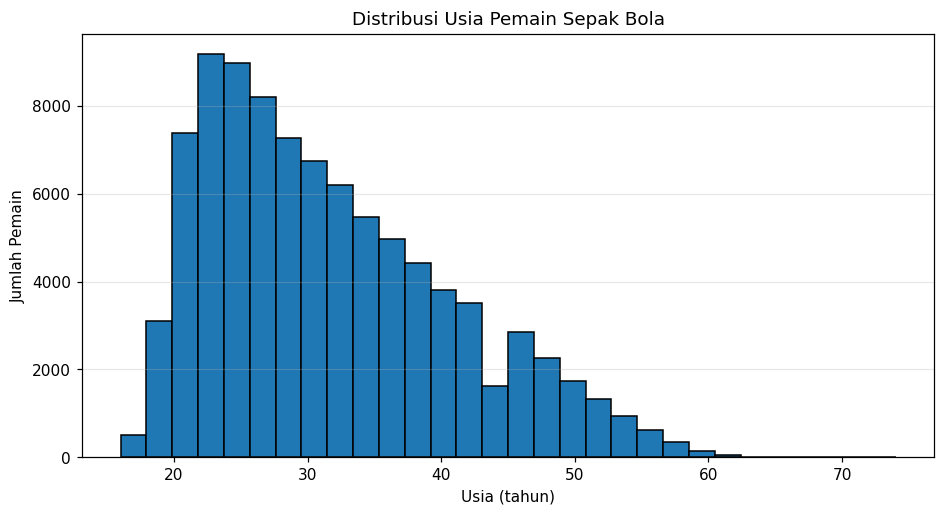

In [32]:
plt.figure(figsize=(10, 5))

plt.hist(
    df["age"].dropna(),
    bins=30,
    edgecolor="black"
)

plt.title("Distribusi Usia Pemain Sepak Bola")
plt.xlabel("Usia (tahun)")
plt.ylabel("Jumlah Pemain")
plt.grid(axis="y", alpha=0.3)
plt.show()

In [33]:
print("Jumlah pemain berusia di atas 50 tahun:")
print((df["age"] > 50).sum())

print("\n20 pemain tertua dalam dataset:")
df.loc[
    df["age"].notna(),
    ["player_name", "date_of_birth", "age", "main_position", "current_club_name"]
].sort_values(
    "age", ascending=False
).head(20)

Jumlah pemain berusia di atas 50 tahun:
3415

20 pemain tertua dalam dataset:


,player_name,date_of_birth,age,main_position,current_club_name
74797,Bram Braam (80070),1952-02-13,74.0,Defender,Retired
44551,Paolo Rosi (369573),1954-02-01,72.0,Midfield,Retired
23937,Les Sealey (176019),1957-09-29,69.0,Goalkeeper,---
77688,Bobby Geddes (74078),1960-08-12,66.0,Goalkeeper,Retired
1310,Benjamín Galindo (102524),1960-12-11,65.0,Midfield,Retired
11149,Alan Knight (128501),1961-06-03,65.0,Goalkeeper,Retired
59663,Santos (555893),1960-12-09,65.0,Midfield,Retired
751,Stuart Pearce (101317),1962-04-24,64.0,Defender,Retired
29315,Kevin Hitchcock (26168),1962-10-05,64.0,Goalkeeper,Retired
61374,Giovan Battista Orlando (574186),1962-06-19,64.0,Midfield,Retired


## 4. Kesimpulan Exploratory Data Analysis (EDA)

Berdasarkan hasil eksplorasi terhadap dataset pemain sepak bola, diperoleh beberapa temuan berikut.

1. **Ukuran dataset:** dataset terdiri dari 92.671 baris dan 34 kolom.
2. **Data duplikat:** tidak ditemukan baris duplikat maupun `player_id` duplikat.
3. **Posisi pemain:** terdapat empat kategori posisi utama, yaitu Defender, Midfield, Attack, dan Goalkeeper, serta 17 kategori posisi spesifik.
4. **Informasi klub:** kolom klub berisi nama klub serta beberapa status khusus, seperti Retired, Without Club, Unknown, dan Career break.
5. **Kewarganegaraan:** terdapat 2.689 nilai kewarganegaraan berbeda. Sebagian data mencantumkan lebih dari satu kewarganegaraan dalam satu kolom.
6. **Tinggi badan:** ditemukan 18.867 nilai tinggi badan sebesar 0 cm dan satu nilai sebesar 2 cm yang perlu ditinjau sebagai data tidak valid.
7. **Kaki dominan:** kategori yang tersedia adalah right, left, dan both. Sebanyak 23.488 baris tidak memiliki informasi kaki dominan.
8. **Usia pemain:** usia berhasil dihitung untuk 91.665 baris, dengan median 30 tahun dan rata-rata sekitar 31,62 tahun berdasarkan tanggal acuan 14 Oktober 2026.
9. **Missing values:** beberapa kolom memiliki nilai kosong dalam jumlah besar, terutama informasi klub tambahan, kontrak, agen pemain, dan media sosial.

Secara keseluruhan, dataset memiliki jumlah data yang memadai untuk dikembangkan menjadi aplikasi pencarian pemain sepak bola. Namun, diperlukan pemilihan fitur dan penanganan data yang sesuai agar informasi yang ditampilkan tetap relevan dan tidak menyesatkan.

## 5. Data Cleaning dan Preprocessing

Tahap data cleaning dan preprocessing dilakukan untuk mempersiapkan dataset sebelum digunakan dalam aplikasi Football Player Finder. Proses ini meliputi pembuatan salinan dataset, pemeriksaan kualitas data, penanganan nilai kosong dan tidak valid, serta penyesuaian format beberapa kolom yang diperlukan oleh sistem pencarian.

Dataset asli tetap dipertahankan agar perubahan selama preprocessing dapat diperiksa dan dibandingkan.

In [34]:
# Membuat salinan dataset untuk proses preprocessing
df_clean = df.copy()

print("Dataset asli :", df.shape)
print("Salinan data :", df_clean.shape)
print("Jumlah baris :", len(df_clean))

Dataset asli : (92671, 35)
Salinan data : (92671, 35)
Jumlah baris : 92671


In [35]:
# Memeriksa kondisi awal salinan dataset
print("Jumlah baris duplikat:", df_clean.duplicated().sum())
print("Jumlah player_id duplikat:", df_clean["player_id"].duplicated().sum())

print("\nJumlah nilai kosong pada kolom penting:")
kolom_penting = [
    "player_name",
    "main_position",
    "position",
    "current_club_name",
    "citizenship",
    "foot",
    "height",
    "date_of_birth",
    "age"
]

print(df_clean[kolom_penting].isnull().sum())

Jumlah baris duplikat: 0
Jumlah player_id duplikat: 0

Jumlah nilai kosong pada kolom penting:
player_name            520
main_position            2
position                 2
current_club_name        0
citizenship             57
foot                 23488
height                   4
date_of_birth         1006
age                   1006
dtype: int64


In [36]:

# Memeriksa nilai tinggi badan yang tidak valid
jumlah_nol = (df_clean["height"] == 0).sum()
jumlah_dua = (df_clean["height"] == 2).sum()

print("Jumlah tinggi badan 0 cm:", jumlah_nol)
print("Jumlah tinggi badan 2 cm:", jumlah_dua)


Jumlah tinggi badan 0 cm: 18867
Jumlah tinggi badan 2 cm: 1


In [37]:

# Mengubah tinggi badan yang tidak valid menjadi nilai kosong
df_clean.loc[df_clean["height"] <= 2, "height"] = np.nan

print("Jumlah tinggi badan yang kosong setelah dibersihkan:")
print(df_clean["height"].isnull().sum())

print("\nJumlah baris setelah pembersihan:", len(df_clean))


Jumlah tinggi badan yang kosong setelah dibersihkan:
18872

Jumlah baris setelah pembersihan: 92671


In [38]:

# Memeriksa data pemain yang tidak memiliki nama atau posisi utama
kolom_identitas = ["player_name", "main_position", "position"]

print("Jumlah nilai kosong sebelum penanganan:")
print(df_clean[kolom_identitas].isnull().sum())

print("\nContoh data tanpa nama pemain:")
display(
    df_clean.loc[
        df_clean["player_name"].isnull(),
        ["player_id", "player_name", "main_position", "position"]
    ].head(10)
)

print("\nContoh data tanpa posisi utama:")
display(
    df_clean.loc[
        df_clean["main_position"].isnull(),
        ["player_id", "player_name", "main_position", "position"]
    ]
)


Jumlah nilai kosong sebelum penanganan:
player_name      520
main_position      2
position           2
dtype: int64

Contoh data tanpa nama pemain:


,player_id,player_name,main_position,position
44,100079,NaN,Midfield,Midfield
46,100080,NaN,Midfield,Midfield
50,100078,NaN,Attack,Attack
342,1005762,NaN,Midfield,Midfield - Central Midfield
852,1016015,NaN,Midfield,Midfield - Defensive Midfield
965,1018365,NaN,Midfield,Midfield - Central Midfield
1067,1020589,NaN,Attack,Attack
1462,1027446,NaN,Attack,Attack - Centre-Forward
1474,102774,NaN,Midfield,Midfield - Central Midfield
1486,1027848,NaN,Midfield,Midfield - Central Midfield



Contoh data tanpa posisi utama:


,player_id,player_name,main_position,position
8023,110139,Jacov Zalevschi (110139),NaN,NaN
41520,380917,Shinobu Ito (380917),NaN,NaN


In [39]:

# Memeriksa jumlah pemain yang memiliki nama dan posisi
nama_tersedia = df_clean["player_name"].notna()
posisi_tersedia = df_clean["main_position"].notna()

print("Pemain dengan nama tersedia:", nama_tersedia.sum())
print("Pemain tanpa nama:", (~nama_tersedia).sum())

print("\nPemain dengan posisi utama tersedia:", posisi_tersedia.sum())
print("Pemain tanpa posisi utama:", (~posisi_tersedia).sum())

print("\nJumlah baris sebelum penanganan:", len(df_clean))


Pemain dengan nama tersedia: 92151
Pemain tanpa nama: 520

Pemain dengan posisi utama tersedia: 92669
Pemain tanpa posisi utama: 2

Jumlah baris sebelum penanganan: 92671


In [40]:

# Memeriksa spasi berlebih pada beberapa kolom teks
kolom_teks = [
    "player_name",
    "main_position",
    "position",
    "current_club_name",
    "citizenship",
    "foot"
]

for kolom in kolom_teks:
    jumlah_spasi = (
        df_clean[kolom]
        .dropna()
        .astype(str)
        .ne(df_clean[kolom].dropna().astype(str).str.strip())
        .sum()
    )
    print(f"{kolom}: {jumlah_spasi} nilai dengan spasi di awal/akhir")


player_name: 0 nilai dengan spasi di awal/akhir
main_position: 0 nilai dengan spasi di awal/akhir
position: 0 nilai dengan spasi di awal/akhir
current_club_name: 0 nilai dengan spasi di awal/akhir
citizenship: 0 nilai dengan spasi di awal/akhir
foot: 0 nilai dengan spasi di awal/akhir


In [41]:

# Memeriksa status khusus pada kolom klub
status_khusus = [
    "Retired",
    "Without Club",
    "Unknown",
    "---",
    "Career break"
]

for status in status_khusus:
    jumlah = (df_clean["current_club_name"] == status).sum()
    print(f"{status}: {jumlah} pemain")

print("\nContoh nama klub yang tercatat:")
display(
    df_clean.loc[
        ~df_clean["current_club_name"].isin(status_khusus),
        ["player_name", "current_club_name", "main_position"]
    ].head(10)
)


Retired: 23380 pemain
Without Club: 8599 pemain
Unknown: 1930 pemain
---: 271 pemain
Career break: 102 pemain

Contoh nama klub yang tercatat:


,player_name,current_club_name,main_position
4,Carlos Auzqui (100001),Club Atlético Tucumán,Attack
6,Matheo Sánchez (1000153),Club Atlético Antoniano,Attack
8,Sergiy Zagynaylov (100020),1.FC Höllental,Attack
9,Lenny Stoltz (1000161),US Mondorf-Les-Bains,Attack
10,Facundo Canete (1000253),Carolina Core FC,Midfield
11,Brian Romero (1000274),Charlotte FC,Attack
12,Nimfasha Berchimas (1000273),Charlotte FC,Attack
13,Malcolm Rangon (1000148),Jura Sud Foot,Defender
14,Mauricio Gonçalves da Moura (1000150),US Chantilly,Defender
15,Joselu Pérez (1000135),Getafe CF B,Attack


In [42]:

# Memilih kolom yang relevan untuk aplikasi Football Player Finder
fitur_pemain = [
    "player_id",
    "player_name",
    "main_position",
    "position",
    "current_club_name",
    "citizenship",
    "foot",
    "height",
    "age"
]

df_pemain = df_clean[fitur_pemain].copy()

print("Ukuran dataset awal :", df_clean.shape)
print("Ukuran dataset fitur:", df_pemain.shape)

display(df_pemain.head(10))


Ukuran dataset awal : (92671, 35)
Ukuran dataset fitur: (92671, 9)


,player_id,player_name,main_position,position,current_club_name,citizenship,foot,height,age
0,1,Silvio Adzic (1),Attack,Attack - Right Winger,Retired,Germany,NaN,NaN,46.0
1,100011,Éverton Silva (100011),Defender,Defender - Right-Back,Without Club,Brazil,right,171.0,38.0
2,10,Miroslav Klose (10),Attack,Attack - Centre-Forward,Retired,Germany,right,184.0,48.0
3,10001,John Thompson (10001),Defender,Defender - Right-Back,Retired,Ireland,both,183.0,45.0
4,100001,Carlos Auzqui (100001),Attack,Attack - Right Winger,Club Atlético Tucumán,Argentina,right,180.0,35.0
5,1000152,Sodick Adejumo (1000152),Midfield,Midfield - Defensive Midfield,Unknown,France Nigeria,right,198.0,22.0
6,1000153,Matheo Sánchez (1000153),Attack,Attack - Left Winger,Club Atlético Antoniano,France,right,186.0,23.0
7,10002,Brian Cash (10002),Midfield,Midfield - Right Midfield,Retired,Ireland,right,175.0,43.0
8,100020,Sergiy Zagynaylov (100020),Attack,Attack - Centre-Forward,1.FC Höllental,Ukraine,left,181.0,35.0
9,1000161,Lenny Stoltz (1000161),Attack,Attack - Centre-Forward,US Mondorf-Les-Bains,France Tunisia,left,182.0,26.0


In [43]:

# Memeriksa kualitas dataset fitur pemain
print("Jumlah nilai kosong setiap kolom:")
display(
    df_pemain.isnull()
    .sum()
    .sort_values(ascending=False)
    .to_frame(name="jumlah_kosong")
)

print("\nJumlah pemain berdasarkan posisi utama:")
display(df_pemain["main_position"].value_counts(dropna=False))

print("\nJumlah kategori kaki dominan:")
display(df_pemain["foot"].value_counts(dropna=False))

print("\nJumlah status klub:")
display(df_pemain["current_club_name"].value_counts().head(10))


Jumlah nilai kosong setiap kolom:


,jumlah_kosong
foot,23488
height,18872
age,1006
player_name,520
citizenship,57
position,2
main_position,2
player_id,0
current_club_name,0



Jumlah pemain berdasarkan posisi utama:


main_position
Defender      29733
Midfield      28373
Attack        24287
Goalkeeper    10276
NaN               2
Name: count, dtype: int64


Jumlah kategori kaki dominan:


foot
right    49186
NaN      23488
left     16870
both      3127
Name: count, dtype: int64


Jumlah status klub:


current_club_name
Retired                   23380
Without Club               8599
Unknown                    1930
---                         271
Career break                102
Arsenal FC                   58
Botafogo FC                  53
Pro Vercelli Primavera       47
Reggiana Primavera           45
Medialiga (RU)               44
Name: count, dtype: int64

In [44]:

# Menyiapkan data pemain yang memiliki nama
df_pencarian = df_pemain.loc[
    df_pemain["player_name"].notna()
].copy()

print("Jumlah seluruh data pemain:", len(df_pemain))
print("Pemain dengan nama tersedia:", len(df_pencarian))
print("Jumlah nama kosong:", df_pencarian["player_name"].isnull().sum())

print("\nContoh data untuk pencarian:")
display(df_pencarian.head(10))


Jumlah seluruh data pemain: 92671
Pemain dengan nama tersedia: 92151
Jumlah nama kosong: 0

Contoh data untuk pencarian:


,player_id,player_name,main_position,position,current_club_name,citizenship,foot,height,age
0,1,Silvio Adzic (1),Attack,Attack - Right Winger,Retired,Germany,NaN,NaN,46.0
1,100011,Éverton Silva (100011),Defender,Defender - Right-Back,Without Club,Brazil,right,171.0,38.0
2,10,Miroslav Klose (10),Attack,Attack - Centre-Forward,Retired,Germany,right,184.0,48.0
3,10001,John Thompson (10001),Defender,Defender - Right-Back,Retired,Ireland,both,183.0,45.0
4,100001,Carlos Auzqui (100001),Attack,Attack - Right Winger,Club Atlético Tucumán,Argentina,right,180.0,35.0
5,1000152,Sodick Adejumo (1000152),Midfield,Midfield - Defensive Midfield,Unknown,France Nigeria,right,198.0,22.0
6,1000153,Matheo Sánchez (1000153),Attack,Attack - Left Winger,Club Atlético Antoniano,France,right,186.0,23.0
7,10002,Brian Cash (10002),Midfield,Midfield - Right Midfield,Retired,Ireland,right,175.0,43.0
8,100020,Sergiy Zagynaylov (100020),Attack,Attack - Centre-Forward,1.FC Höllental,Ukraine,left,181.0,35.0
9,1000161,Lenny Stoltz (1000161),Attack,Attack - Centre-Forward,US Mondorf-Les-Bains,France Tunisia,left,182.0,26.0


In [45]:

# Membuat teks gabungan untuk sistem pencarian
kolom_teks_pencarian = [
    "player_name",
    "main_position",
    "position",
    "current_club_name",
    "citizenship",
    "foot"
]

df_pencarian["search_text"] = (
    df_pencarian[kolom_teks_pencarian]
    .fillna("")
    .astype(str)
    .agg(" ".join, axis=1)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

print("Jumlah data pencarian:", len(df_pencarian))
print("Jumlah teks pencarian kosong:",
      df_pencarian["search_text"].eq("").sum())

print("\nContoh teks pencarian:")
display(
    df_pencarian[
        ["player_name", "main_position", "current_club_name",
         "citizenship", "search_text"]
    ].head(10)
)


Jumlah data pencarian: 92151
Jumlah teks pencarian kosong: 0

Contoh teks pencarian:


,player_name,main_position,current_club_name,citizenship,search_text
0,Silvio Adzic (1),Attack,Retired,Germany,Silvio Adzic (1) Attack Attack - Right Winger ...
1,Éverton Silva (100011),Defender,Without Club,Brazil,Éverton Silva (100011) Defender Defender - Rig...
2,Miroslav Klose (10),Attack,Retired,Germany,Miroslav Klose (10) Attack Attack - Centre-For...
3,John Thompson (10001),Defender,Retired,Ireland,John Thompson (10001) Defender Defender - Righ...
4,Carlos Auzqui (100001),Attack,Club Atlético Tucumán,Argentina,Carlos Auzqui (100001) Attack Attack - Right W...
5,Sodick Adejumo (1000152),Midfield,Unknown,France Nigeria,Sodick Adejumo (1000152) Midfield Midfield - D...
6,Matheo Sánchez (1000153),Attack,Club Atlético Antoniano,France,Matheo Sánchez (1000153) Attack Attack - Left ...
7,Brian Cash (10002),Midfield,Retired,Ireland,Brian Cash (10002) Midfield Midfield - Right M...
8,Sergiy Zagynaylov (100020),Attack,1.FC Höllental,Ukraine,Sergiy Zagynaylov (100020) Attack Attack - Cen...
9,Lenny Stoltz (1000161),Attack,US Mondorf-Les-Bains,France Tunisia,Lenny Stoltz (1000161) Attack Attack - Centre-...


## 6. Implementasi TF-IDF

TF-IDF (*Term Frequency-Inverse Document Frequency*) merupakan metode untuk mengubah teks menjadi representasi numerik berdasarkan kemunculan kata dalam dokumen dan tingkat keunikan kata tersebut di seluruh dokumen.

Pada proyek Football Player Finder, TF-IDF digunakan untuk mengubah teks profil pemain menjadi vektor angka. Hasilnya akan digunakan dalam proses perhitungan kemiripan profil pemain.

In [46]:

# Mengimpor dan membuat model TF-IDF
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    lowercase=True,
    stop_words=None,
    max_features=50000
)

tfidf_matrix = tfidf.fit_transform(df_pencarian["search_text"])

print("Jumlah pemain:", tfidf_matrix.shape[0])
print("Jumlah fitur teks:", tfidf_matrix.shape[1])
print("Ukuran matriks TF-IDF:", tfidf_matrix.shape)


Jumlah pemain: 92151
Jumlah fitur teks: 50000
Ukuran matriks TF-IDF: (92151, 50000)


In [47]:

# Menguji kemiripan profil pemain menggunakan Cosine Similarity
from sklearn.metrics.pairwise import cosine_similarity

indeks_pemain = 0

skor_kemiripan = cosine_similarity(
    tfidf_matrix[indeks_pemain],
    tfidf_matrix
).flatten()

# Mengurutkan pemain dari yang paling mirip
indeks_teratas = skor_kemiripan.argsort()[::-1]

# Mengambil 5 hasil selain pemain yang sedang diuji
indeks_teratas = [
    i for i in indeks_teratas if i != indeks_pemain
][:5]

hasil_kemiripan = df_pencarian.iloc[indeks_teratas][
    ["player_name", "main_position", "position", "current_club_name"]
].copy()

hasil_kemiripan["similarity_score"] = [
    skor_kemiripan[i] for i in indeks_teratas
]

print("Pemain yang diuji:")
display(
    df_pencarian.iloc[[indeks_pemain]][
        ["player_name", "main_position", "position", "current_club_name"]
    ]
)

print("\nLima profil pemain paling mirip:")
display(hasil_kemiripan)


Pemain yang diuji:


,player_name,main_position,position,current_club_name
0,Silvio Adzic (1),Attack,Attack - Right Winger,Retired



Lima profil pemain paling mirip:


,player_name,main_position,position,current_club_name,similarity_score
23838,Silvio (174957),Goalkeeper,Goalkeeper,Retired,0.472892
86636,Silvio Romero (88082),Attack,Attack - Centre-Forward,Without Club,0.442311
59205,Silvio González (55190),Attack,Attack - Centre-Forward,Retired,0.434261
49415,Silvio Merkaj (460842),Attack,Attack - Centre-Forward,FC Südtirol,0.429904
59025,Silvio Rudman (549595),Attack,Attack - Centre-Forward,Retired,0.402617


In [48]:

# Membuat teks profil tanpa nama pemain
kolom_profil = [
    "main_position",
    "position",
    "current_club_name",
    "citizenship",
    "foot"
]

df_pencarian["profile_text"] = (
    df_pencarian[kolom_profil]
    .fillna("")
    .astype(str)
    .agg(" ".join, axis=1)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

# Membuat model TF-IDF baru berdasarkan karakteristik pemain
tfidf_profil = TfidfVectorizer(
    lowercase=True,
    max_features=50000
)

matriks_profil = tfidf_profil.fit_transform(
    df_pencarian["profile_text"]
)

# Menguji pemain yang sama
skor_profil = cosine_similarity(
    matriks_profil[0],
    matriks_profil
).flatten()

# Mengambil lima pemain paling mirip, tanpa pemain itu sendiri
urutan = skor_profil.argsort()[::-1]
urutan = [i for i in urutan if i != 0][:5]

hasil_profil = df_pencarian.iloc[urutan][
    ["player_name", "main_position", "position",
     "current_club_name", "citizenship", "foot"]
].copy()

hasil_profil["similarity_score"] = [skor_profil[i] for i in urutan]

print("Pemain yang diuji:")
display(
    df_pencarian.iloc[[0]][
        ["player_name", "main_position", "position",
         "current_club_name", "citizenship", "foot"]
    ]
)

print("\nLima pemain dengan profil teks paling mirip:")
display(hasil_profil)


Pemain yang diuji:


,player_name,main_position,position,current_club_name,citizenship,foot
0,Silvio Adzic (1),Attack,Attack - Right Winger,Retired,Germany,NaN



Lima pemain dengan profil teks paling mirip:


,player_name,main_position,position,current_club_name,citizenship,foot,similarity_score
37770,Sebastian Stachnik (32621),Attack,Attack - Right Winger,Retired,Germany,NaN,1.000000
55239,Christian Timm (51),Attack,Attack - Right Winger,Retired,Germany,NaN,1.000000
6862,Albert Streit (1080),Attack,Attack - Right Winger,Retired,Germany,NaN,1.000000
19321,Björn Ziegenbein (15553),Attack,Attack - Right Winger,Retired,Germany,NaN,1.000000
82700,Ben Zolinski (93841),Attack,Attack - Right Winger,Retired,Germany,right,0.981525


In [49]:

# Membandingkan teks profil pemain yang diuji dengan hasil teratas
print("Teks profil pemain yang diuji:")
print(df_pencarian.iloc[0]["profile_text"])

print("\nTeks profil lima hasil teratas:")
for i in urutan:
    print("\nNama:", df_pencarian.iloc[i]["player_name"])
    print("Teks:", df_pencarian.iloc[i]["profile_text"])
    print("Skor kemiripan:", round(skor_profil[i], 6))


Teks profil pemain yang diuji:
Attack Attack - Right Winger Retired Germany

Teks profil lima hasil teratas:

Nama: Sebastian Stachnik (32621)
Teks: Attack Attack - Right Winger Retired Germany
Skor kemiripan: 1.0

Nama: Christian Timm (51)
Teks: Attack Attack - Right Winger Retired Germany
Skor kemiripan: 1.0

Nama: Albert Streit (1080)
Teks: Attack Attack - Right Winger Retired Germany
Skor kemiripan: 1.0

Nama: Björn Ziegenbein (15553)
Teks: Attack Attack - Right Winger Retired Germany
Skor kemiripan: 1.0

Nama: Ben Zolinski (93841)
Teks: Attack Attack - Right Winger Retired Germany right
Skor kemiripan: 0.981525


In [50]:

# Membuat teks profil yang menyertakan usia dan tinggi badan
df_pencarian["profile_text_v2"] = (
    df_pencarian[
        [
            "main_position",
            "position",
            "current_club_name",
            "citizenship",
            "foot"
        ]
    ]
    .fillna("")
    .astype(str)
    .agg(" ".join, axis=1)
    .str.cat(
        (
            " age_" + df_pencarian["age"].round().astype("Int64").astype(str)
        ).where(df_pencarian["age"].notna(), ""),
        na_rep=""
    )
    .str.cat(
        (
            " height_" + df_pencarian["height"].round().astype("Int64").astype(str)
        ).where(df_pencarian["height"].notna(), ""),
        na_rep=""
    )
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

print("Contoh teks profil baru:")
display(
    df_pencarian[
        ["player_name", "age", "height", "profile_text_v2"]
    ].head(10)
)


Contoh teks profil baru:


,player_name,age,height,profile_text_v2
0,Silvio Adzic (1),46.0,NaN,Attack Attack - Right Winger Retired Germany a...
1,Éverton Silva (100011),38.0,171.0,Defender Defender - Right-Back Without Club Br...
2,Miroslav Klose (10),48.0,184.0,Attack Attack - Centre-Forward Retired Germany...
3,John Thompson (10001),45.0,183.0,Defender Defender - Right-Back Retired Ireland...
4,Carlos Auzqui (100001),35.0,180.0,Attack Attack - Right Winger Club Atlético Tuc...
5,Sodick Adejumo (1000152),22.0,198.0,Midfield Midfield - Defensive Midfield Unknown...
6,Matheo Sánchez (1000153),23.0,186.0,Attack Attack - Left Winger Club Atlético Anto...
7,Brian Cash (10002),43.0,175.0,Midfield Midfield - Right Midfield Retired Ire...
8,Sergiy Zagynaylov (100020),35.0,181.0,Attack Attack - Centre-Forward 1.FC Höllental ...
9,Lenny Stoltz (1000161),26.0,182.0,Attack Attack - Centre-Forward US Mondorf-Les-...


In [51]:

# Membuat model TF-IDF berdasarkan profil pemain versi kedua
tfidf_profil_v2 = TfidfVectorizer(
    lowercase=True,
    max_features=50000
)

matriks_profil_v2 = tfidf_profil_v2.fit_transform(
    df_pencarian["profile_text_v2"]
)

# Menghitung kemiripan dengan pemain pertama
skor_profil_v2 = cosine_similarity(
    matriks_profil_v2[0],
    matriks_profil_v2
).flatten()

# Mengambil lima hasil teratas selain pemain yang diuji
urutan_v2 = skor_profil_v2.argsort()[::-1]
urutan_v2 = [i for i in urutan_v2 if i != 0][:5]

hasil_profil_v2 = df_pencarian.iloc[urutan_v2][
    [
        "player_name",
        "main_position",
        "position",
        "current_club_name",
        "age",
        "height"
    ]
].copy()

hasil_profil_v2["similarity_score"] = [
    skor_profil_v2[i] for i in urutan_v2
]

print("Pemain yang diuji:")
display(
    df_pencarian.iloc[[0]][
        ["player_name", "main_position", "position", "age", "height"]
    ]
)

print("\nLima hasil teratas model versi kedua:")
display(hasil_profil_v2)


Pemain yang diuji:


,player_name,main_position,position,age,height
0,Silvio Adzic (1),Attack,Attack - Right Winger,46.0,NaN



Lima hasil teratas model versi kedua:


,player_name,main_position,position,current_club_name,age,height,similarity_score
6862,Albert Streit (1080),Attack,Attack - Right Winger,Retired,46.0,NaN,1.000000
19354,Steffen Handschuh (1558),Attack,Attack - Centre-Forward,Retired,46.0,NaN,0.838304
27563,Holm Hentschke (2081),Attack,Attack - Centre-Forward,Retired,46.0,NaN,0.838304
88087,Andreas Gerdes-Wurpts (8364),Attack,Attack - Centre-Forward,Retired,46.0,NaN,0.838304
73655,Markus Daun (67),Attack,Attack - Centre-Forward,Retired,46.0,185.0,0.787212


In [52]:

# Membuat fungsi rekomendasi pemain berdasarkan kemiripan profil
def rekomendasi_pemain(nama_pemain, jumlah_rekomendasi=5):
    hasil_cari = df_pencarian[
        df_pencarian["player_name"].str.contains(
            nama_pemain,
            case=False,
            na=False,
            regex=False
        )
    ]

    if hasil_cari.empty:
        print(f"Pemain dengan nama '{nama_pemain}' tidak ditemukan.")
        return

    indeks_target = hasil_cari.index[0]
    posisi_target = df_pencarian.index.get_loc(indeks_target)

    skor = cosine_similarity(
        matriks_profil_v2[posisi_target],
        matriks_profil_v2
    ).flatten()

    urutan = skor.argsort()[::-1]
    urutan = [i for i in urutan if i != posisi_target]
    urutan = urutan[:jumlah_rekomendasi]

    hasil = df_pencarian.iloc[urutan][
        [
            "player_name",
            "main_position",
            "position",
            "current_club_name",
            "age",
            "height"
        ]
    ].copy()

    hasil["similarity_score"] = [skor[i] for i in urutan]

    print("Pemain yang dicari:")
    display(
        df_pencarian.iloc[[posisi_target]][
            [
                "player_name",
                "main_position",
                "position",
                "current_club_name",
                "age",
                "height"
            ]
        ]
    )

    print("\nRekomendasi pemain:")
    display(hasil)

# Menguji fungsi
rekomendasi_pemain("Silvio Adzic", 5)


Pemain yang dicari:


,player_name,main_position,position,current_club_name,age,height
0,Silvio Adzic (1),Attack,Attack - Right Winger,Retired,46.0,NaN



Rekomendasi pemain:


,player_name,main_position,position,current_club_name,age,height,similarity_score
6862,Albert Streit (1080),Attack,Attack - Right Winger,Retired,46.0,NaN,1.000000
19354,Steffen Handschuh (1558),Attack,Attack - Centre-Forward,Retired,46.0,NaN,0.838304
27563,Holm Hentschke (2081),Attack,Attack - Centre-Forward,Retired,46.0,NaN,0.838304
88087,Andreas Gerdes-Wurpts (8364),Attack,Attack - Centre-Forward,Retired,46.0,NaN,0.838304
73655,Markus Daun (67),Attack,Attack - Centre-Forward,Retired,46.0,185.0,0.787212


In [53]:

# Menguji pencarian pemain yang tidak ada dalam dataset
rekomendasi_pemain("NamaPemainTidakAda123", 5)


Pemain dengan nama 'NamaPemainTidakAda123' tidak ditemukan.


In [54]:

# Membuat fungsi untuk mencari kandidat pemain berdasarkan nama
def cari_pemain(nama_pemain, batas_hasil=10):
    hasil = df_pencarian[
        df_pencarian["player_name"].str.contains(
            nama_pemain,
            case=False,
            na=False,
            regex=False
        )
    ][
        [
            "player_id",
            "player_name",
            "main_position",
            "position",
            "current_club_name",
            "age",
            "height"
        ]
    ].head(batas_hasil)

    if hasil.empty:
        print(f"Pemain dengan nama '{nama_pemain}' tidak ditemukan.")
    else:
        print(f"Jumlah kandidat yang ditampilkan: {len(hasil)}")
        display(hasil)

# Menguji pencarian nama pemain
cari_pemain("Silvio", 10)


Jumlah kandidat yang ditampilkan: 10


,player_id,player_name,main_position,position,current_club_name,age,height
0,1,Silvio Adzic (1),Attack,Attack - Right Winger,Retired,46.0,NaN
12165,1310489,Silvio Cambrini (1310489),Midfield,Midfield - Attacking Midfield,Napoli Under 18,18.0,NaN
14477,1159,Silvio Schröter (1159),Midfield,Midfield - Right Midfield,Retired,47.0,180.0
18792,150,Silvio Meißner (150),Midfield,Midfield - Defensive Midfield,Retired,53.0,NaN
23838,174957,Silvio (174957),Goalkeeper,Goalkeeper,Retired,38.0,196.0
26974,20197,Silvio Enrique (20197),Midfield,Midfield,Retired,47.0,169.0
26985,202076,Silvio (202076),Defender,Defender - Centre-Back,Clube Náutico Marcílio Dias (SC),38.0,180.0
37000,317123,Silvio Vertullo (317123),Defender,Defender,Retired,46.0,NaN
38651,33545,Silvio Bär (33545),Defender,Defender - Centre-Back,Retired,43.0,NaN
40402,309593,Silvio Giusti (309593),Midfield,Midfield - Central Midfield,Retired,58.0,180.0


In [55]:

from sklearn.metrics.pairwise import cosine_similarity

def rekomendasi_berdasarkan_id(player_id, jumlah_rekomendasi=5):
    # Mencari posisi pemain berdasarkan ID
    hasil_cari = df_pencarian.index[
        df_pencarian["player_id"] == player_id
    ]

    # Memeriksa apakah ID tersedia
    if len(hasil_cari) == 0:
        print(f"Pemain dengan ID {player_id} tidak ditemukan.")
        return

    indeks_target = df_pencarian.index.get_loc(hasil_cari[0])

    # Menghitung kemiripan profil pemain
    skor = cosine_similarity(
        matriks_profil_v2[indeks_target],
        matriks_profil_v2
    ).flatten()

    # Mengurutkan pemain dari skor kemiripan tertinggi
    urutan = skor.argsort()[::-1]
    urutan = [
        i for i in urutan
        if i != indeks_target
    ][:jumlah_rekomendasi]

    # Menampilkan informasi pemain yang dipilih
    kolom_tampilan = [
        "player_id",
        "player_name",
        "main_position",
        "position",
        "current_club_name",
        "age",
        "height"
    ]

    print("Pemain yang dipilih:")
    display(df_pencarian.iloc[[indeks_target]][kolom_tampilan])

    # Menampilkan hasil rekomendasi
    hasil = df_pencarian.iloc[urutan][kolom_tampilan].copy()
    hasil["similarity_score"] = [skor[i] for i in urutan]

    print("Rekomendasi pemain:")
    display(hasil)

# Menguji rekomendasi untuk Silvio Adzic
rekomendasi_berdasarkan_id(1, 5)


Pemain yang dipilih:


,player_id,player_name,main_position,position,current_club_name,age,height
0,1,Silvio Adzic (1),Attack,Attack - Right Winger,Retired,46.0,NaN


Rekomendasi pemain:


,player_id,player_name,main_position,position,current_club_name,age,height,similarity_score
6862,1080,Albert Streit (1080),Attack,Attack - Right Winger,Retired,46.0,NaN,1.000000
19354,1558,Steffen Handschuh (1558),Attack,Attack - Centre-Forward,Retired,46.0,NaN,0.838304
27563,2081,Holm Hentschke (2081),Attack,Attack - Centre-Forward,Retired,46.0,NaN,0.838304
88087,8364,Andreas Gerdes-Wurpts (8364),Attack,Attack - Centre-Forward,Retired,46.0,NaN,0.838304
73655,67,Markus Daun (67),Attack,Attack - Centre-Forward,Retired,46.0,185.0,0.787212


In [56]:

# Menguji ID pemain yang tidak tersedia dalam dataset
rekomendasi_berdasarkan_id(999999999, 5)


Pemain dengan ID 999999999 tidak ditemukan.
